In [1]:
import itertools
import torch
import matplotlib.pyplot as plt

from data import HousesDataset
from models import LinearRegressionModel
from learners import RegressionLearner
from utilities import plot_house_results

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print('device:', device)

device: cpu


In [2]:
## PARAMETERS
random_seed = 1
epochs = 25
learning_rates = [0.01, 0.1, 0.25]   # <-- pick the 3 you want to compare
batch_sizes = [32, 64]
train_dataset_size = 5000
test_dataset_size = 20

## DATA (default dataset sizes)
train_dataset = HousesDataset(train_dataset_size)
test_dataset = HousesDataset(test_dataset_size)

print("train data shape:", tuple(train_dataset.data.shape))
print("test data shape:", tuple(test_dataset.data.shape))

train data shape: (5000, 1)
test data shape: (20, 1)


In [3]:
results = {}   # (batch_size, lr) -> dict with losses, final test loss, learned params

for batch_size, lr in itertools.product(batch_sizes, learning_rates):
    print(f"--- batch_size={batch_size}, lr={lr} ---")

    # reseed so every run starts from the same initial weights / batch order
    torch.manual_seed(random_seed)
    torch.cuda.manual_seed(random_seed)

    train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size)

    # fresh model, criterion and optimizer for every run
    model = LinearRegressionModel()
    criterion = torch.nn.L1Loss()
    optimizer = torch.optim.SGD(model.parameters(), lr)

    learner = RegressionLearner(model, criterion, optimizer)
    train_losses = learner.train(train_dataloader, epochs, device)

    # load best parameters of THIS run (the "leader" checkpoint is overwritten each run)
    learner.load("leader")

    results[(batch_size, lr)] = {
        "train_losses": train_losses,
        "train_loss": learner.test(train_dataset, device),
        "test_loss": learner.test(test_dataset, device),
        "weight": model.linear_layer.weight.data[0].item(),
        "bias": model.linear_layer.bias.data[0].item(),
        "model": model,
        "learner": learner,
    }

--- batch_size=32, lr=0.01 ---
train epoch [1/25]:	train loss = 345336.694400
train epoch [2/25]:	train loss = 341481.247350
train epoch [3/25]:	train loss = 337625.801900
train epoch [4/25]:	train loss = 333770.357050
train epoch [5/25]:	train loss = 329914.904650
train epoch [6/25]:	train loss = 326059.451600
train epoch [7/25]:	train loss = 322204.003150
train epoch [8/25]:	train loss = 318348.559950
train epoch [9/25]:	train loss = 314493.122550
train epoch [10/25]:	train loss = 310637.683500
train epoch [11/25]:	train loss = 306782.241100
train epoch [12/25]:	train loss = 302926.800650
train epoch [13/25]:	train loss = 299071.361550
train epoch [14/25]:	train loss = 295215.903550
train epoch [15/25]:	train loss = 291360.459300
train epoch [16/25]:	train loss = 287505.012050
train epoch [17/25]:	train loss = 283649.565900
train epoch [18/25]:	train loss = 279794.118900
train epoch [19/25]:	train loss = 275938.675500
train epoch [20/25]:	train loss = 272083.229150
train epoch [21/25

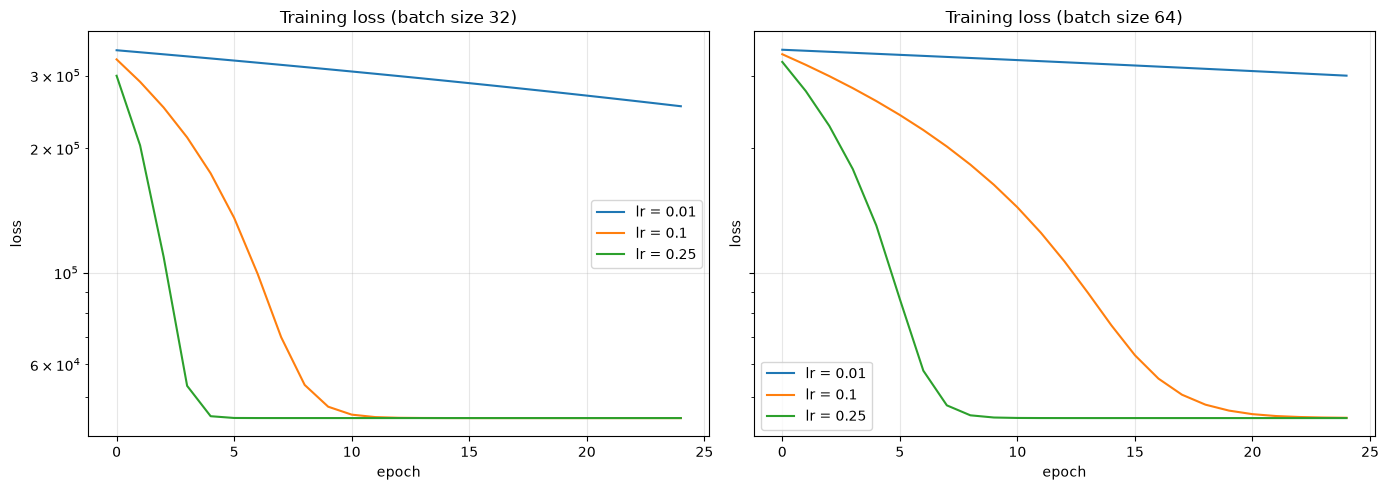

In [4]:
fig, axes = plt.subplots(1, len(batch_sizes), figsize=(7 * len(batch_sizes), 5), sharey=True)

for ax, batch_size in zip(axes, batch_sizes):
    for lr in learning_rates:
        ax.plot(results[(batch_size, lr)]["train_losses"], label=f"lr = {lr}")
    ax.set_title(f"Training loss (batch size {batch_size})")
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.set_yscale("log")   # remove if you prefer a linear axis
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [5]:
# summary of all 6 runs  (true function: 5000 * x + 100000)
print(f"{'batch':>5} {'lr':>6} {'train loss':>12} {'test loss':>12} {'weight':>10} {'bias':>12}")
for (bs, lr), r in results.items():
    print(f"{bs:>5} {lr:>6} {r['train_loss']:>12.2f} {r['test_loss']:>12.2f} {r['weight']:>10.1f} {r['bias']:>12.1f}")

batch     lr   train loss    test loss     weight         bias
   32   0.01       500.86       506.21     1945.0         38.8
   32    0.1       210.94       200.80     6891.5        157.2
   32   0.25       210.94       200.67     6893.6        200.1
   64   0.01       546.59       547.76      978.7         19.3
   64    0.1       211.07       203.45     6833.9        141.8
   64   0.25       210.94       200.63     6895.4        164.7
